# Carregar os dados e separar treino/teste
O notebook de modelagem precisa ser independente do notebook anterior e utilizar a mesma divisão dos dados, sem consultar as respostas do conjunto de teste durante o treinamento.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Localizar o projeto
raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent

# Carregar dados originais
df = pd.read_csv(
    raiz / "data" / "raw" / "payflow_credit_risk.csv"
)

# Variáveis excluídas na etapa de preparação
colunas_excluidas = [
    "id_cliente",
    "default_90d",
    "parcelas_pagas_ate_3m",
    "atraso_primeira_parcela_dias",
    "status_apos_90d",
    "juros_mensal_pct"
]

X = df.drop(columns=colunas_excluidas)
y = df["default_90d"]

# Reproduzir a divisão utilizada anteriormente
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

Treinamento: (4000, 17)
Teste: (1000, 17)


# Criar e treinar o baseline
Precisamos de uma referência mínima para comparar os modelos mais avançados. Como a maioria dos clientes não apresenta default, esse modelo ajuda a demonstrar por que a acurácia sozinha pode ser enganosa.

Utiliza DummyClassifier para criar um modelo simples que sempre prevê a classe mais frequente no treinamento.

In [2]:
import sys
from pathlib import Path

# Identificar a pasta principal do projeto
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

# Permitir importar arquivos da pasta src
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# Importar a função criada anteriormente
from src.features.preprocessing import criar_preprocessador

print("Função importada com sucesso!")

Função importada com sucesso!


In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

# Criar o pipeline com o pré-processamento e o modelo
baseline = Pipeline(steps=[
    ("preprocessamento", criar_preprocessador(X_treino)),
    ("modelo", DummyClassifier(strategy="most_frequent"))
])

# Treinar o modelo
baseline.fit(X_treino, y_treino)

# Gerar previsões
previsoes_baseline = baseline.predict(X_treino)

print("Baseline treinado com sucesso!")

Baseline treinado com sucesso!


# Avaliar o baseline no treinamento
Queremos registrar o comportamento do modelo de referência antes de compará-lo com modelos que realmente aprendem padrões.

Calcula a matriz de confusão, acurácia, precision, recall e F1-score do baseline nos dados de treinamento.

In [4]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Avaliação inicial nos dados de treinamento
print(
    "Acurácia:",
    round(accuracy_score(y_treino, previsoes_baseline), 4)
)

print(
    "Precision:",
    round(precision_score(
        y_treino, previsoes_baseline, zero_division=0
    ), 4)
)

print(
    "Recall:",
    round(recall_score(
        y_treino, previsoes_baseline, zero_division=0
    ), 4)
)

print(
    "F1-score:",
    round(f1_score(
        y_treino, previsoes_baseline, zero_division=0
    ), 4)
)

print("\nMatriz de confusão:")
print(confusion_matrix(y_treino, previsoes_baseline))

Acurácia: 0.8782
Precision: 0.0
Recall: 0.0
F1-score: 0.0

Matriz de confusão:
[[3513    0]
 [ 487    0]]


# Treinar a Regressão Logística
Diferentemente do Dummy Classifier, a Regressão Logística aprende relações entre características dos clientes e a probabilidade de inadimplência.

Cria e treina uma Regressão Logística utilizando os mesmos dados e o mesmo método de pré-processamento do baseline.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Criar o pipeline completo de classificação
modelo_logistico = Pipeline(steps=[
    ("preprocessamento", criar_preprocessador(X_treino)),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Treinar com os dados de treinamento
modelo_logistico.fit(X_treino, y_treino)

print("Regressão Logística treinada com sucesso!")

Regressão Logística treinada com sucesso!


# Gerar previsões
Precisamos avaliar a capacidade do modelo de identificar clientes que apresentam default.

Calcula as probabilidades de inadimplência e as classificações do modelo nos dados de treinamento.

In [6]:
# Probabilidade estimada para a classe 1 (default)
probabilidades_logistica = modelo_logistico.predict_proba(
    X_treino
)[:, 1]

# Classificações com threshold padrão de 0,5
previsoes_logistica = modelo_logistico.predict(X_treino)

print("Primeiras probabilidades:")
print(probabilidades_logistica[:10])

Primeiras probabilidades:
[0.09421663 0.16922059 0.07918303 0.04437855 0.33946946 0.0168738
 0.17421735 0.06095331 0.530372   0.15030388]


# Avaliar a Regressão Logística
Essas métricas permitirão comparar a Regressão Logística com o baseline.

Calcula acurácia, precision, recall, F1-score e ROC-AUC.

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Acurácia:", round(
    accuracy_score(y_treino, previsoes_logistica), 4
))

print("Precision:", round(
    precision_score(y_treino, previsoes_logistica, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_treino, previsoes_logistica, zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_treino, previsoes_logistica, zero_division=0), 4
))

print("ROC-AUC:", round(
    roc_auc_score(y_treino, probabilidades_logistica), 4
))

print("\nMatriz de confusão:")
print(confusion_matrix(y_treino, previsoes_logistica))

Acurácia: 0.8858
Precision: 0.6154
Recall: 0.1643
F1-score: 0.2593
ROC-AUC: 0.7877

Matriz de confusão:
[[3463   50]
 [ 407   80]]


# Validação cruzada
Divide os 4.000 registros de treinamento em cinco partes, treina o modelo repetidamente e calcula métricas em cada divisão.

Reduz a dependência de uma única divisão dos dados e fornece uma estimativa mais confiável da capacidade de generalização.

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# Configurar validação cruzada com 5 divisões
validacao = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Métricas utilizadas
metricas = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, zero_division=0
    ),
    "recall": make_scorer(
        recall_score, zero_division=0
    ),
    "f1": make_scorer(
        f1_score, zero_division=0
    ),
    "roc_auc": "roc_auc"
}

# Avaliar o modelo completo, incluindo pré-processamento
resultados_cv = cross_validate(
    modelo_logistico,
    X_treino,
    y_treino,
    cv=validacao,
    scoring=metricas,
    n_jobs=-1
)

# Exibir as médias das métricas
for metrica in metricas:
    valores = resultados_cv[f"test_{metrica}"]

    print(
        f"{metrica}: "
        f"{valores.mean():.4f} "
        f"(± {valores.std():.4f})"
    )

accuracy: 0.8825 (± 0.0048)
precision: 0.5729 (± 0.0779)
recall: 0.1580 (± 0.0318)
f1: 0.2453 (± 0.0402)
roc_auc: 0.7762 (± 0.0333)


# Decision Tree Classifier
Verificar se relações não lineares entre as variáveis conseguem melhorar a identificação de inadimplentes.

Um algoritmo que aprende regras de decisão, por exemplo, combinando score de crédito, atrasos anteriores e outras características para classificar o risco.

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Criar pipeline de Árvore de Decisão
modelo_arvore = Pipeline(steps=[
    ("preprocessamento", criar_preprocessador(X_treino)),
    ("modelo", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Treinar com os dados de treinamento
modelo_arvore.fit(X_treino, y_treino)

print("Árvore de Decisão treinada com sucesso!")

Árvore de Decisão treinada com sucesso!


Por que essas configurações? max_depth=5 limita a profundidade da árvore e min_samples_leaf=20 exige pelo menos 20 registros em cada folha. São configurações iniciais propostas para reduzir a complexidade, não parâmetros comprovadamente ideais.

# Validar a Árvore de Decisão
Permite comparar os dois algoritmos em condições equivalentes e sem utilizar o conjunto de teste final.

Utiliza as mesmas cinco divisões e métricas da Regressão Logística.

In [10]:
# Avaliar a árvore com a mesma validação cruzada
resultados_arvore_cv = cross_validate(
    modelo_arvore,
    X_treino,
    y_treino,
    cv=validacao,
    scoring=metricas,
    n_jobs=-1
)

# Exibir as médias e os desvios-padrão
for metrica in metricas:
    valores = resultados_arvore_cv[f"test_{metrica}"]

    print(
        f"{metrica}: "
        f"{valores.mean():.4f} "
        f"(± {valores.std():.4f})"
    )

accuracy: 0.8812 (± 0.0027)
precision: 0.5373 (± 0.0314)
recall: 0.1663 (± 0.0254)
f1: 0.2536 (± 0.0330)
roc_auc: 0.7400 (± 0.0355)


# Treinar o Random Forest
Queremos testar um algoritmo mais flexível, capaz de representar relações não lineares e interações entre variáveis.

Cria uma floresta com 200 árvores, aplica o pré-processamento existente e ajusta o modelo nos dados de treinamento.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Criar o modelo Random Forest
modelo_floresta = Pipeline(steps=[
    ("preprocessamento", criar_preprocessador(X_treino)),
    ("modelo", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Treinar o modelo
modelo_floresta.fit(X_treino, y_treino)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


# Validar o Random Forest
manter condições equivalentes de comparação, ajustando o pré-processamento separadamente dentro de cada divisão.

Aplica a mesma validação cruzada de cinco divisões e calcula as mesmas métricas utilizadas nos modelos anteriores.

In [12]:
# Executar validação cruzada
resultados_floresta_cv = cross_validate(
    modelo_floresta,
    X_treino,
    y_treino,
    cv=validacao,
    scoring=metricas,
    n_jobs=1
)

# Exibir resultados
for metrica in metricas:
    valores = resultados_floresta_cv[f"test_{metrica}"]

    print(
        f"{metrica}: "
        f"{valores.mean():.4f} "
        f"(± {valores.std():.4f})"
    )

accuracy: 0.8785 (± 0.0005)
precision: 0.2333 (± 0.2906)
recall: 0.0061 (± 0.0082)
f1: 0.0120 (± 0.0159)
roc_auc: 0.7727 (± 0.0316)


# O que os resultados significam?

A Regressão Logística continua sendo a melhor candidata inicial considerando o ROC-AUC. Isso é interessante porque também é um modelo relativamente interpretável, algo importante para decisões de crédito.

A Árvore de Decisão apresentou o maior recall e F1-score, mas as diferenças em relação à Regressão Logística são pequenas.

O Random Forest apresentou um comportamento importante: seu ROC-AUC foi de 0,7727, próximo ao da Regressão Logística, mas seu recall foi de apenas 0,61%.

Isso significa que, com o threshold padrão de 0,5, o Random Forest praticamente não identifica clientes inadimplentes, embora consiga ordenar os riscos razoavelmente bem.

Não devemos descartar o Random Forest ainda. Esse resultado sugere que precisamos investigar as probabilidades e o threshold de classificação antes de selecionar definitivamente o melhor algoritmo.

Também vale observar que a precisão do Random Forest variou bastante entre as cinco divisões, indicando instabilidade nessa métrica.

# Validar o Dummy Classifier
Garante que a comparação seja justa, sem misturar métricas calculadas no treinamento completo com métricas de validação cruzada.

Avalia o baseline nas mesmas cinco divisões de treinamento.

In [13]:
# Avaliar o Dummy Classifier com validação cruzada
resultados_baseline_cv = cross_validate(
    baseline,
    X_treino,
    y_treino,
    cv=validacao,
    scoring=metricas,
    n_jobs=-1
)

# Exibir resultados
for metrica in metricas:
    valores = resultados_baseline_cv[f"test_{metrica}"]

    print(
        f"{metrica}: "
        f"{valores.mean():.4f} "
        f"(± {valores.std():.4f})"
    )

accuracy: 0.8782 (± 0.0006)
precision: 0.0000 (± 0.0000)
recall: 0.0000 (± 0.0000)
f1: 0.0000 (± 0.0000)
roc_auc: 0.5000 (± 0.0000)


# Criar uma tabela comparativa automática
Facilita a interpretação, a documentação e a escolha dos candidatos que seguiremos avaliando.

Reúne as métricas dos quatro modelos em uma tabela.

In [14]:
# Reunir os resultados dos quatro modelos
resultados_modelos = {
    "Dummy Classifier": resultados_baseline_cv,
    "Regressão Logística": resultados_cv,
    "Árvore de Decisão": resultados_arvore_cv,
    "Random Forest": resultados_floresta_cv
}

# Construir tabela comparativa
comparacao = pd.DataFrame({
    nome: {
        metrica: resultado[f"test_{metrica}"].mean()
        for metrica in metricas
    }
    for nome, resultado in resultados_modelos.items()
}).T

# Mostrar resultados em percentual, exceto ROC-AUC
display(comparacao.round(4))

,accuracy,precision,recall,f1,roc_auc
Dummy Classifier,0.8782,0.0000,0.0000,0.0000,0.5000
Regressão Logística,0.8825,0.5729,0.1580,0.2453,0.7762
Árvore de Decisão,0.8812,0.5373,0.1663,0.2536,0.7400
Random Forest,0.8785,0.2333,0.0061,0.0120,0.7727


# O que vamos fazer?
Vamos investigar como a Regressão Logística se comporta quando alteramos o limite utilizado para classificar um cliente como inadimplente.

Por exemplo:
- Threshold de 0,50: classifica como inadimplente quando a probabilidade estimada é de pelo menos 50%.
- Threshold de 0,30: classifica como inadimplente quando a probabilidade é de pelo menos 30%.
- Threshold de 0,20: classifica como inadimplente quando a probabilidade é de pelo menos 20%.
Diminuir o threshold normalmente aumenta o recall, mas também pode aumentar os falsos positivos.

# Gerar probabilidades com validação cruzada
Permite analisar diferentes thresholds sem utilizar as previsões feitas pelo modelo sobre os próprios dados em que foi treinado.

Gera uma probabilidade de inadimplência para cada registro, utilizando um modelo treinado sem aquele registro.

In [15]:
from sklearn.model_selection import cross_val_predict

# Gerar probabilidades fora de cada divisão de treinamento
probabilidades_cv = cross_val_predict(
    modelo_logistico,
    X_treino,
    y_treino,
    cv=validacao,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Probabilidades geradas:", len(probabilidades_cv))
print("Primeiras probabilidades:", probabilidades_cv[:10])

Probabilidades geradas: 4000
Primeiras probabilidades: [0.08926859 0.16855796 0.08259036 0.05890571 0.30289765 0.01701882
 0.16784531 0.06571408 0.59049285 0.14354316]


# Comparar diferentes thresholds
Precisamos entender qual limite oferece um equilíbrio adequado entre identificar clientes inadimplentes e evitar classificações incorretas.

Calcula precision, recall, F1-score e quantidade de falsos positivos e falsos negativos para vários thresholds.

In [16]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

resultados_thresholds = []

for threshold in thresholds:

    previsoes = (probabilidades_cv >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_treino,
        previsoes,
        labels=[0, 1]
    ).ravel()

    resultados_thresholds.append({
        "threshold": threshold,
        "precision": precision_score(
            y_treino, previsoes, zero_division=0
        ),
        "recall": recall_score(
            y_treino, previsoes, zero_division=0
        ),
        "f1": f1_score(
            y_treino, previsoes, zero_division=0
        ),
        "falsos_positivos": fp,
        "falsos_negativos": fn,
        "verdadeiros_positivos": tp,
        "verdadeiros_negativos": tn
    })

comparacao_thresholds = pd.DataFrame(resultados_thresholds)

display(comparacao_thresholds.round(4))

,threshold,precision,recall,f1,falsos_positivos,falsos_negativos,verdadeiros_positivos,verdadeiros_negativos
0,0.10,0.2385,0.7351,0.3602,1143,129,358,2370
1,0.15,0.3118,0.5852,0.4069,629,202,285,2884
2,0.20,0.3670,0.4702,0.4122,395,258,229,3118
3,0.25,0.4205,0.3963,0.4080,266,294,193,3247
4,0.30,0.4765,0.3326,0.3918,178,325,162,3335
5,0.40,0.5164,0.2259,0.3143,103,377,110,3410
6,0.50,0.5620,0.1581,0.2468,60,410,77,3453


# Visualizar o comportamento das métricas
Constrói um gráfico mostrando como precision, recall e F1-score mudam conforme alteramos o threshold.

Facilita visualizar o equilíbrio entre identificar inadimplentes e reduzir alertas incorretos.

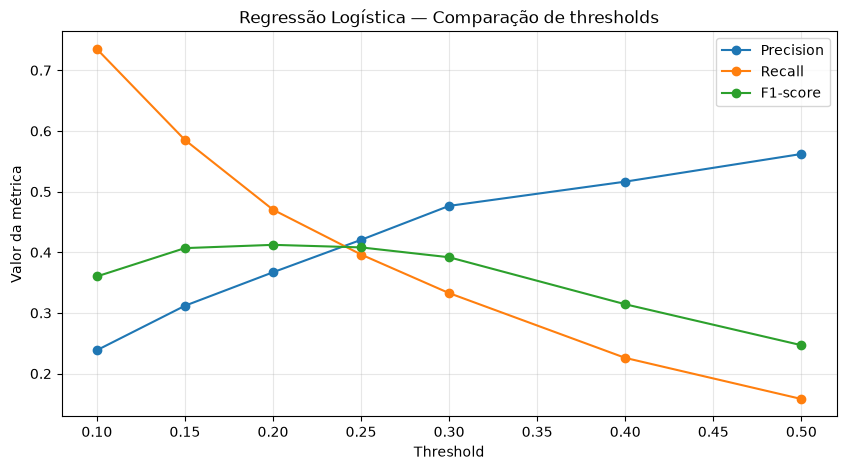

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    comparacao_thresholds["threshold"],
    comparacao_thresholds["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    comparacao_thresholds["threshold"],
    comparacao_thresholds["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    comparacao_thresholds["threshold"],
    comparacao_thresholds["f1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Threshold")
plt.ylabel("Valor da métrica")
plt.title("Regressão Logística — Comparação de thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Gerar a comparação
Verificar se os outros algoritmos também podem melhorar o recall e o F1-score quando deixamos de utilizar o limite padrão de 0,50.

Gera probabilidades fora das divisões de treinamento para os três modelos e calcula suas métricas nos mesmos thresholds.

In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

modelos = {
    "Regressão Logística": modelo_logistico,
    "Árvore de Decisão": modelo_arvore,
    "Random Forest": modelo_floresta
}

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

resultados = []

for nome, modelo in modelos.items():

    # Gerar probabilidades por validação cruzada
    probabilidades = cross_val_predict(
        modelo,
        X_treino,
        y_treino,
        cv=validacao,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    for threshold in thresholds:

        previsoes = (probabilidades >= threshold).astype(int)

        resultados.append({
            "modelo": nome,
            "threshold": threshold,
            "precision": precision_score(
                y_treino, previsoes, zero_division=0
            ),
            "recall": recall_score(
                y_treino, previsoes, zero_division=0
            ),
            "f1": f1_score(
                y_treino, previsoes, zero_division=0
            )
        })

comparacao_geral = pd.DataFrame(resultados)

display(comparacao_geral.round(4))

,modelo,threshold,precision,recall,f1
0,Regressão Logística,0.10,0.2385,0.7351,0.3602
1,Regressão Logística,0.15,0.3118,0.5852,0.4069
2,Regressão Logística,0.20,0.3670,0.4702,0.4122
3,Regressão Logística,0.25,0.4205,0.3963,0.4080
4,Regressão Logística,0.30,0.4765,0.3326,0.3918
5,Regressão Logística,0.40,0.5164,0.2259,0.3143
6,Regressão Logística,0.50,0.5620,0.1581,0.2468
7,Árvore de Decisão,0.10,0.2709,0.6263,0.3782
8,Árvore de Decisão,0.15,0.2919,0.5688,0.3858
9,Árvore de Decisão,0.20,0.3369,0.4497,0.3852


# Identificar o melhor F1 de cada modelo
Gerar uma comparação inicial e orientar quais combinações de modelo e threshold merecem investigação adicional.

Identifica o threshold com maior F1-score observado para cada algoritmo.

In [19]:
melhores_indices = comparacao_geral.groupby("modelo")["f1"].idxmax()

melhores_resultados = comparacao_geral.loc[
    melhores_indices
].sort_values("f1", ascending=False)

display(melhores_resultados.round(4))

,modelo,threshold,precision,recall,f1
16,Random Forest,0.20,0.3699,0.4990,0.4248
2,Regressão Logística,0.20,0.3670,0.4702,0.4122
8,Árvore de Decisão,0.15,0.2919,0.5688,0.3858


# Registrar a escolha no notebook

In [20]:
# Configuração selecionada
modelo_final = modelo_logistico
threshold_final = 0.20

print("Modelo:", modelo_final.named_steps["modelo"].__class__.__name__)
print("Threshold:", threshold_final)
print("Critério de seleção: F1-score e ROC-AUC")

Modelo: LogisticRegression
Threshold: 0.2
Critério de seleção: F1-score e ROC-AUC


# Avaliação final nos dados de teste

Agora que a configuração está definida, podemos utilizar pela primeira vez os 1.000 registros reservados para teste.

Precisamos verificar se o desempenho observado na validação cruzada também se mantém em dados que não participaram do treinamento ou da escolha do threshold.

Calcula as probabilidades de default no conjunto de teste, aplica o threshold escolhido e apresenta as métricas finais.

In [21]:
# Gerar probabilidades no conjunto de teste
probabilidades_teste = modelo_final.predict_proba(
    X_teste
)[:, 1]

# Aplicar o threshold selecionado
previsoes_teste = (
    probabilidades_teste >= threshold_final
).astype(int)

# Avaliar desempenho final
metricas_finais = {
    "Acurácia": accuracy_score(y_teste, previsoes_teste),
    "Precision": precision_score(
        y_teste, previsoes_teste, zero_division=0
    ),
    "Recall": recall_score(
        y_teste, previsoes_teste, zero_division=0
    ),
    "F1-score": f1_score(
        y_teste, previsoes_teste, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_teste, probabilidades_teste
    )
}

for nome, valor in metricas_finais.items():
    print(f"{nome}: {valor:.4f}")

print("\nMatriz de confusão:")
print(confusion_matrix(y_teste, previsoes_teste))

Acurácia: 0.8270
Precision: 0.3376
Recall: 0.4344
F1-score: 0.3799
ROC-AUC: 0.7202

Matriz de confusão:
[[774 104]
 [ 69  53]]


# Calcular o Brier Score
A PayFlow precisa de estimativas de risco confiáveis, não apenas de classificações 0 e 1.

Mede a diferença quadrática média entre as probabilidades previstas e os resultados reais.

In [22]:
from sklearn.metrics import brier_score_loss

# Calibração nas previsões de validação cruzada
brier_cv = brier_score_loss(
    y_treino,
    probabilidades_cv
)

# Calibração no teste final, apenas para diagnóstico
brier_teste = brier_score_loss(
    y_teste,
    probabilidades_teste
)

print(f"Brier Score CV: {brier_cv:.4f}")
print(f"Brier Score teste: {brier_teste:.4f}")

Brier Score CV: 0.0911
Brier Score teste: 0.0977


# Criar a curva de calibração
Permite identificar se o modelo tende a superestimar ou subestimar o risco.

Compara as probabilidades médias previstas com a proporção real de inadimplência em grupos de clientes.

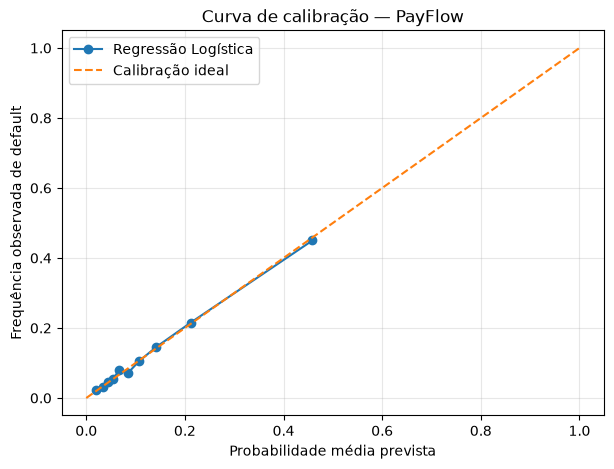

In [23]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Utilizar as previsões de validação cruzada
fracao_positivos, media_prevista = calibration_curve(
    y_treino,
    probabilidades_cv,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))

plt.plot(
    media_prevista,
    fracao_positivos,
    marker="o",
    label="Regressão Logística"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibração ideal"
)

plt.xlabel("Probabilidade média prevista")
plt.ylabel("Frequência observada de default")
plt.title("Curva de calibração — PayFlow")
plt.legend()
plt.grid(alpha=0.3)
plt.show()